In [1]:
from pathlib import Path
from factor_analyzer import Rotator, calculate_bartlett_sphericity, calculate_kmo
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.decomposition import KernelPCA, PCA
from sklearn.manifold import TSNE, Isomap, trustworthiness
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import StandardScaler
import umap

DATA_PATH = Path("data") / "data.csv"
data = pd.read_csv(DATA_PATH)

cols = [f'k{i}' for i in range(1, 21) if f"k{i}" in data.columns]

independent_cols = cols.copy()
independent_cols.remove('k8')  # see lab1: r(k5, k8) = -0.9972
independent_data = data[independent_cols].copy()

print(f"Removed {data.shape[1] - independent_data.shape[1]} components: {[col for col in data.columns if col not in independent_data.columns]}")

Removed 4 components: ['Cреднеспис.числ.работн', 'k4_new', 'k8', 'Year']


In [2]:
scaler = StandardScaler()
standard_data = scaler.fit_transform(independent_data)

chi_square, p_value = calculate_bartlett_sphericity(standard_data)
kmo_per_var, kmo_total = calculate_kmo(standard_data)

criteria = pd.DataFrame({
    'Criteria': [
        'KMO statistic',
        'Bartlett sphericity χ²',
        'Bartlett sphericity p-value'
    ],
    'Value': [
        f"{kmo_total:.4f}",
        f"{chi_square:.4f}",
        f"{p_value:.4f}"
    ]
})

display(criteria)

low_kmo_vars = pd.DataFrame({
    'Variable': independent_data.columns,
    'KMO': np.round(kmo_per_var, 4)
}).sort_values(by='KMO')

print("\nVariables with KMO < 0.5:")
display(low_kmo_vars[low_kmo_vars['KMO'] < 0.5])

,Criteria,Value
0,KMO statistic,0.7225
1,Bartlett sphericity χ²,25262.7658
2,Bartlett sphericity p-value,0.0000



Variables with KMO < 0.5:


,Variable,KMO
13,k15,0.4303


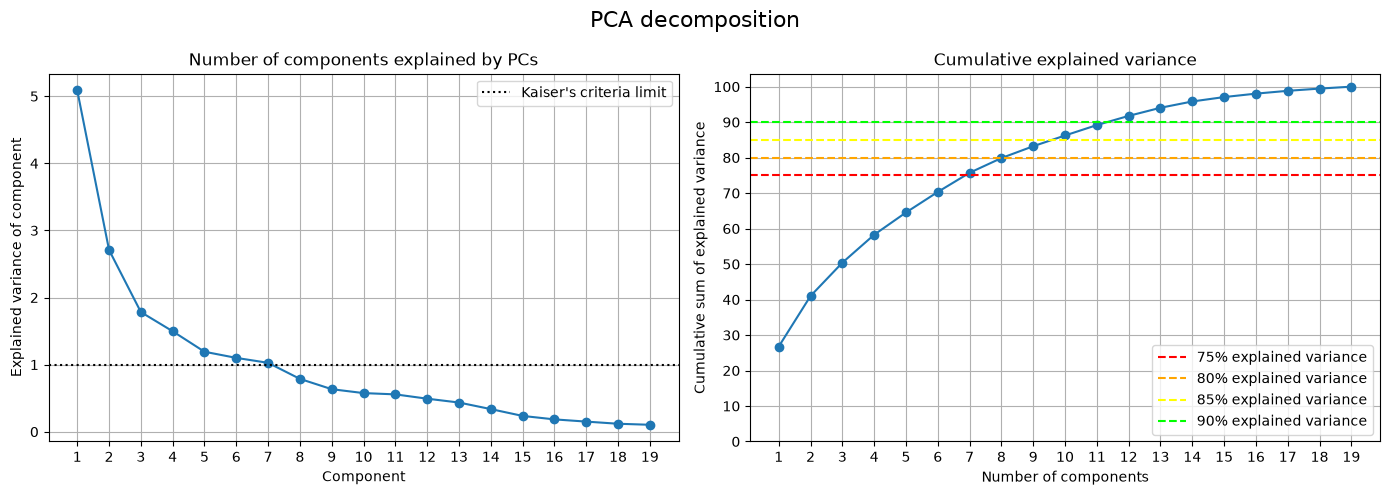

In [3]:
pca = PCA()
data_pca = pca.fit_transform(standard_data)

x = range(1, 20)
y = pca.explained_variance_

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(x, y, marker='o')
plt.axhline(y=1, xmin=0, xmax=1, linestyle=':', color='black', label="Kaiser's criteria limit")
plt.grid(True)
plt.legend()
plt.xticks(x)
plt.xlabel("Component")
plt.ylabel("Explained variance of component")
plt.title("Number of components explained by PCs")

x = range(1, 20)
y = np.cumsum(pca.explained_variance_ratio_) * 100

plt.subplot(1, 2, 2)
plt.plot(x, y, marker='o')
plt.axhline(y=75, linestyle='--', color='red', label="75% explained variance")
plt.axhline(y=80, linestyle='--', color='orange', label="80% explained variance")
plt.axhline(y=85, linestyle='--', color='yellow', label="85% explained variance")
plt.axhline(y=90, linestyle='--', color='lime', label="90% explained variance")
plt.grid(True)
plt.legend(loc="lower right")
plt.xticks(x)
plt.yticks(range(0, 101, 10))
plt.xlabel("Number of components")
plt.ylabel("Cumulative sum of explained variance")
plt.title("Cumulative explained variance")

plt.suptitle("PCA decomposition", fontsize=16)
plt.tight_layout()
plt.show()

,communality_7,communality_8,communality_10
k1,0.829202,0.836399,0.836967
k2,0.793584,0.793615,0.806896
k3,0.877683,0.877705,0.900573
k4,0.721723,0.756472,0.894138
k5,0.847951,0.874718,0.911536
k6,0.751623,0.775709,0.822907
k7,0.623299,0.654745,0.758921
k9,0.757760,0.779990,0.904149
k10,0.727495,0.733202,0.904164
k11,0.660874,0.688317,0.828241


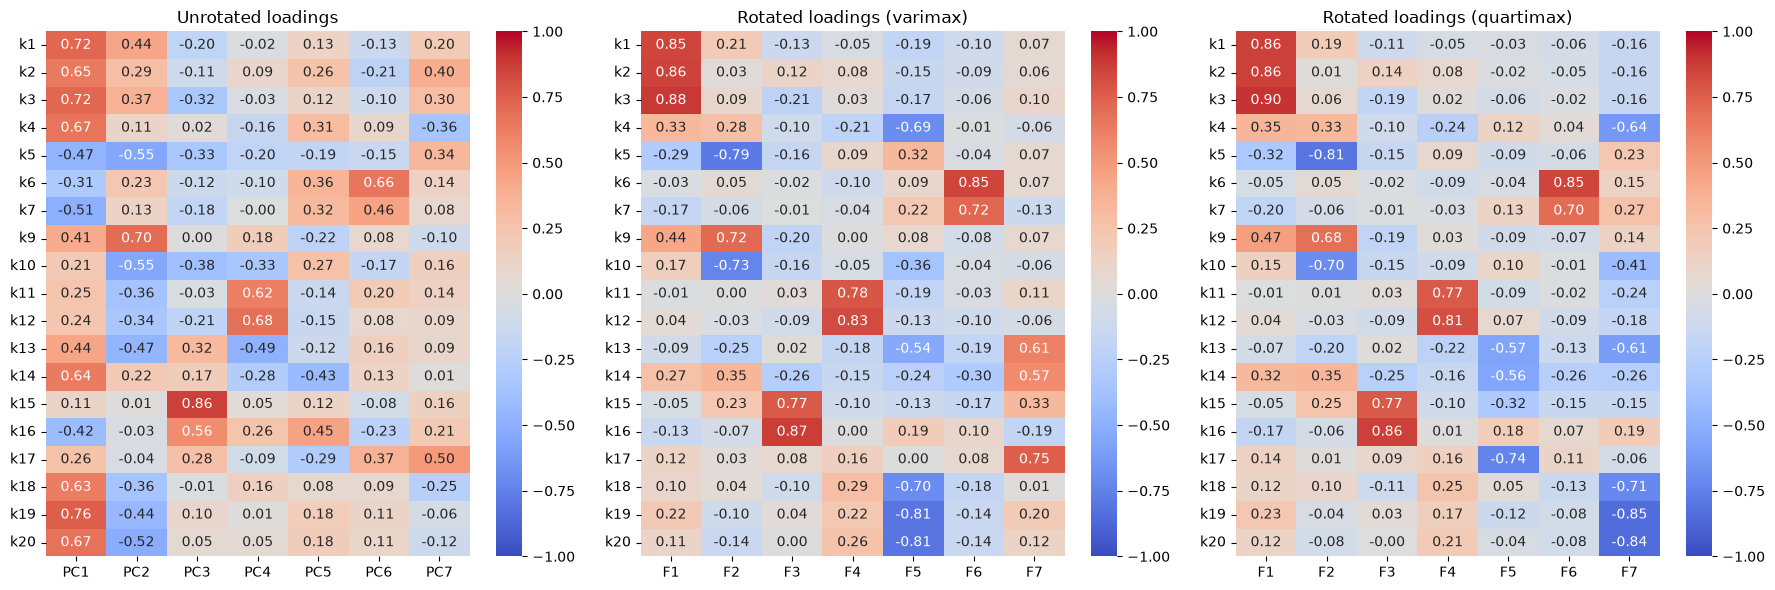

In [4]:
factor_loadings = pd.DataFrame(pca.components_.T * np.sqrt(pca.explained_variance_), index = independent_data.columns, columns=[f'PC{i}' for i in range(1, 20)])

communality_7 = factor_loadings.iloc[:, :7].pow(2).sum(axis=1)
communality_8 = factor_loadings.iloc[:, :8].pow(2).sum(axis=1)
communality_10 = factor_loadings.iloc[:, :10].pow(2).sum(axis=1)
communalities = pd.DataFrame((communality_7, communality_8, communality_10), index=[f'communality_{i}' for i in [7, 8, 10]]).T
display(communalities)

plt.figure(figsize=(18, 6))

plt.subplot(1, 3, 1)
plt.title("Unrotated loadings")
sns.heatmap(factor_loadings.iloc[:, :7], annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)

plt.subplot(1, 3, 2)
plt.title("Rotated loadings (varimax)")
rotator_varimax = Rotator()
varimax_loadings = pd.DataFrame(rotator_varimax.fit_transform(factor_loadings.iloc[:, :7]), index=independent_data.columns, columns=[f'F{i}' for i in range(1, 8)])
sns.heatmap(varimax_loadings, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)

plt.subplot(1, 3, 3)
plt.title("Rotated loadings (quartimax)")
rotator_quartimax = Rotator(method='quartimax')
quartimax_loadings = pd.DataFrame(rotator_quartimax.fit_transform(factor_loadings.iloc[:, :7]), index=independent_data.columns, columns=[f'F{i}' for i in range(1, 8)])
sns.heatmap(quartimax_loadings, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.tight_layout()
plt.show()

,count,mean,std,min,25%,50%,75%,max
Creditworthiness,2537.0,0.0,0.8914,-3.1573,-0.5791,-0.1516,0.4099,5.6808


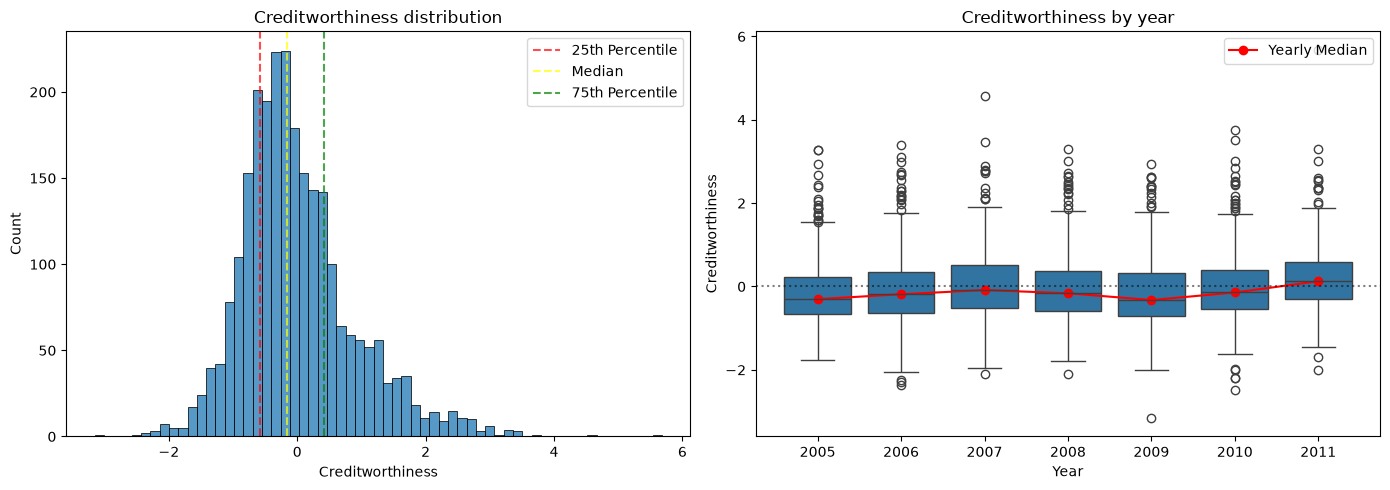

In [5]:
weights_retained = pca.explained_variance_ratio_[:7]
weights = weights_retained / sum(weights_retained)

creditworthiness = pd.DataFrame((data_pca[:, :7] * weights).sum(axis=1), columns=['Creditworthiness'])
display(creditworthiness.describe().round(4).T)

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
sns.histplot(creditworthiness['Creditworthiness'])
q25, q50, q75 = creditworthiness['Creditworthiness'].quantile([0.25, 0.50, 0.75])
plt.axvline(x=q25, linestyle='--', color='red', alpha=0.7, label="25th Percentile")
plt.axvline(x=q50, linestyle='--', color='yellow', alpha=0.7, label="Median")
plt.axvline(x=q75, linestyle='--', color='green', alpha=0.7, label="75th Percentile")
plt.title("Creditworthiness distribution")
plt.legend(loc="upper right")

plt.subplot(1, 2, 2)
years = pd.Series(map(int, (2000 + data['Year'])))
scores = creditworthiness['Creditworthiness']
sns.boxplot(x=years, y=scores)
medians = scores.groupby(years).median()
plt.plot(range(len(medians)), medians, color='red', marker='o', label='Yearly Median')
plt.axhline(y=0, linestyle=':', color='black', alpha=0.5)
plt.title("Creditworthiness by year")
plt.xlabel("Year")
plt.ylabel("Creditworthiness")
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()

In [6]:
score = trustworthiness(standard_data, data_pca[:, :7], n_neighbors=5)
print("Linear PCA:\n - Trustworthiness:", score)

def scorer_func(estimator, X):
    return trustworthiness(X, estimator.transform(X), n_neighbors=5)

def run_grid_search(data, estimator, param_grid):
    grid = GridSearchCV(estimator=estimator, param_grid=param_grid, scoring=scorer_func, cv=5)
    grid.fit(data)
    print(" - Best parameters:", grid.best_params_)
    print(" - Trustworthiness:", grid.best_score_)
    return pd.DataFrame(grid.cv_results_)[['params', 'mean_test_score', 'std_test_score', 'rank_test_score']].sort_values(by='rank_test_score')

print("\nKernelPCA:")
param_grid = {'kernel': ['rbf', 'poly', 'sigmoid', 'cosine'], 'gamma': [0.001, 0.01, 0.05, 0.1, 0.5]}
results_kernel_pca = run_grid_search(data=standard_data, estimator=KernelPCA(n_components=7), param_grid=param_grid)
display(results_kernel_pca)

print("\nIsomap:")
param_grid = {'n_neighbors': [5, 10, 15, 20, 30]}
results_isomap = run_grid_search(data=standard_data, estimator=Isomap(n_components=7), param_grid=param_grid)
display(results_isomap)

print("\nUMAP:")
param_grid = {'n_neighbors': [5, 15, 30], 'min_dist': [0.1, 0.5]}
results_umap = run_grid_search(data=standard_data, estimator=umap.UMAP(n_components=7), param_grid=param_grid)
display(results_umap)

print("\nt-SNE:")
tsne_results = []
for p in [10, 30, 50]:
    X_tsne = TSNE(n_components=2, perplexity=p).fit_transform(standard_data)
    t_score = trustworthiness(standard_data, X_tsne, n_neighbors=5)
    tsne_results.append({'perplexity': p, 'trustworthiness_score': t_score})

results_tsne = pd.DataFrame(tsne_results).sort_values(by='trustworthiness_score', ascending=False)
display(results_tsne)

print("\nSummary:")
summary = pd.DataFrame([
    {'Model': 'Linear PCA', 'Best Parameters': 'n_components=7', 'Trustworthiness': score},
    {'Model': 'KernelPCA', 'Best Parameters': str(results_kernel_pca.iloc[0]['params']), 'Trustworthiness': results_kernel_pca.iloc[0]['mean_test_score']},
    {'Model': 'Isomap', 'Best Parameters': str(results_isomap.iloc[0]['params']), 'Trustworthiness': results_isomap.iloc[0]['mean_test_score']},
    {'Model': 'UMAP', 'Best Parameters': str(results_umap.iloc[0]['params']), 'Trustworthiness': results_umap.iloc[0]['mean_test_score']},
    {'Model': 't-SNE', 'Best Parameters': f"perplexity={results_tsne.iloc[0]['perplexity']:.0f}", 'Trustworthiness': results_tsne.iloc[0]['trustworthiness_score']}
]).sort_values(by='Trustworthiness', ascending=False).round(4)

display(summary)

Linear PCA:
 - Trustworthiness: 0.9859140006667629

KernelPCA:
 - Best parameters: {'gamma': 0.01, 'kernel': 'sigmoid'}
 - Trustworthiness: 0.9787883923388874


,params,mean_test_score,std_test_score,rank_test_score
6,"{'gamma': 0.01, 'kernel': 'sigmoid'}",0.978788,0.006238,1
10,"{'gamma': 0.05, 'kernel': 'sigmoid'}",0.977047,0.003921,2
2,"{'gamma': 0.001, 'kernel': 'sigmoid'}",0.975533,0.009338,3
1,"{'gamma': 0.001, 'kernel': 'poly'}",0.974550,0.010407,4
0,"{'gamma': 0.001, 'kernel': 'rbf'}",0.973089,0.011866,5
14,"{'gamma': 0.1, 'kernel': 'sigmoid'}",0.973021,0.003659,6
4,"{'gamma': 0.01, 'kernel': 'rbf'}",0.966446,0.009278,7
5,"{'gamma': 0.01, 'kernel': 'poly'}",0.959380,0.015511,8
18,"{'gamma': 0.5, 'kernel': 'sigmoid'}",0.947244,0.009197,9
8,"{'gamma': 0.05, 'kernel': 'rbf'}",0.929731,0.008590,10



Isomap:
 - Best parameters: {'n_neighbors': 30}
 - Trustworthiness: 0.9730550151980489


,params,mean_test_score,std_test_score,rank_test_score
4,{'n_neighbors': 30},0.973055,0.016309,1
3,{'n_neighbors': 20},0.970411,0.017173,2
2,{'n_neighbors': 15},0.967938,0.017937,3
1,{'n_neighbors': 10},0.965709,0.016118,4
0,{'n_neighbors': 5},0.954633,0.015565,5



UMAP:
 - Best parameters: {'min_dist': 0.5, 'n_neighbors': 15}
 - Trustworthiness: 0.9558296246365285


,params,mean_test_score,std_test_score,rank_test_score
4,"{'min_dist': 0.5, 'n_neighbors': 15}",0.955830,0.009710,1
5,"{'min_dist': 0.5, 'n_neighbors': 30}",0.955783,0.012374,2
3,"{'min_dist': 0.5, 'n_neighbors': 5}",0.941773,0.013142,3
2,"{'min_dist': 0.1, 'n_neighbors': 30}",0.939575,0.013682,4
1,"{'min_dist': 0.1, 'n_neighbors': 15}",0.937877,0.011798,5
0,"{'min_dist': 0.1, 'n_neighbors': 5}",0.922615,0.012828,6



t-SNE:


,perplexity,trustworthiness_score
0,10,0.982479
1,30,0.981523
2,50,0.979391



Summary:


,Model,Best Parameters,Trustworthiness
0,Linear PCA,n_components=7,0.9859
4,t-SNE,perplexity=10,0.9825
1,KernelPCA,"{'gamma': 0.01, 'kernel': 'sigmoid'}",0.9788
2,Isomap,{'n_neighbors': 30},0.9731
3,UMAP,"{'min_dist': 0.5, 'n_neighbors': 15}",0.9558
